# Chapter 1: You Already Do Mathematics

*Math Class Didn't Show Its Work* by Jason Karpeles

In this notebook you will see how everyday sorting turns into mathematics once the rule is written down clearly enough for someone else to test. You will test rules on the numbers 4, 6, 8, 9, watch a list fall out of date while a rule keeps up, sort six message cards with two overlapping rules, and give every number in a small collection exactly one location.

**A note before you start.** The code cells are optional reading. You do not need to run or understand them: the numbers and pictures they produce are already shown right below each one. If you are curious, read the code like a recipe, one line at a time.

In [1]:
%matplotlib inline
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.patches import Rectangle, Circle, FancyBboxPatch

INK, TEAL, GOLD, RED, GREY, NAVY = "#172a3b", "#0f6268", "#b8860b", "#a24a33", "#6b757b", "#1f3b5c"
PALE, PICK = "#e3efee", "#f3e1da"
plt.rcParams.update({"figure.dpi": 100, "font.size": 11, "axes.edgecolor": GREY,
                     "axes.labelcolor": INK, "text.color": INK})

def blank(ax):
    """Hide ticks and frame so a drawing looks like a drawing."""
    ax.set_xticks([]); ax.set_yticks([])
    for side in ax.spines.values():
        side.set_visible(False)

def as_set(items):
    """Write a collection the way the book does: {3, 6, 9}."""
    items = list(items)
    return "{" + ", ".join(str(i) for i in items) + "}" if items else "{ }"

yn = lambda b: "yes" if b else "no"

## 1. More than one number can be the odd one out

**The question.** In 4, 6, 8, 9, which number does not belong, and what rule makes that choice checkable?

**The equations from the chapter.**

$$4, 6, 8, 9 \qquad\qquad 8 = 2 \times 2 \times 2$$

**What the symbols mean.** A *cube number* is a whole number multiplied by itself three times, so $8 = 2 \times 2 \times 2$. A *square number* is a whole number times itself, like $3 \times 3 = 9$. *Even* means the number splits into pairs with nothing left over; *odd* means one is left over.

**Try to predict first.** If the rule were "is odd", which of the four numbers would light up?

The rule we start with is **"the number is a cube number."** Each number gets the same yes-or-no question.

In [2]:
numbers = [4, 6, 8, 9]

def cube_chain(n):
    """Try 1 x 1 x 1, 2 x 2 x 2, ... until we reach or pass n."""
    tries, k = [], 1
    while k ** 3 <= n:
        tries.append(f"{k} x {k} x {k} = {k**3}")
        k += 1
    tries.append(f"{k} x {k} x {k} = {k**3}")
    return tries, any(k ** 3 == n for k in range(1, n + 1))

print("Rule: the number is a cube number (some whole number times itself three times).")
for n in numbers:
    tries, ok = cube_chain(n)
    print(f"  {n}: " + ", ".join(tries) + f"  ->  {'hits ' + str(n) + ': YES' if ok else 'skips ' + str(n) + ': no'}")

passes = [n for n in numbers if cube_chain(n)[1]]
print()
print("Numbers that pass:", as_set(passes))
print("Numbers that fail:", as_set([n for n in numbers if n not in passes]))
print("The one that does not belong:", passes[0])
print()
print("Reason: 8 = 2 x 2 x 2, while 4 = 2 x 2 and 9 = 3 x 3 are squares and 6 is neither.")

Rule: the number is a cube number (some whole number times itself three times).
  4: 1 x 1 x 1 = 1, 2 x 2 x 2 = 8  ->  skips 4: no
  6: 1 x 1 x 1 = 1, 2 x 2 x 2 = 8  ->  skips 6: no
  8: 1 x 1 x 1 = 1, 2 x 2 x 2 = 8, 3 x 3 x 3 = 27  ->  hits 8: YES
  9: 1 x 1 x 1 = 1, 2 x 2 x 2 = 8, 3 x 3 x 3 = 27  ->  skips 9: no

Numbers that pass: {8}
Numbers that fail: {4, 6, 9}
The one that does not belong: 8

Reason: 8 = 2 x 2 x 2, while 4 = 2 x 2 and 9 = 3 x 3 are squares and 6 is neither.


The book's other three rules work the same way. Each one asks all four numbers the same question, and exactly one says yes.

In [3]:
rules = {
    "is a cube number":                  lambda n: round(n ** (1 / 3)) ** 3 == n,
    "is odd":                            lambda n: n % 2 == 1,
    "is neither a square nor a cube":    lambda n: round(n ** 0.5) ** 2 != n and round(n ** (1 / 3)) ** 3 != n,
    "is an even square":                 lambda n: n % 2 == 0 and round(n ** 0.5) ** 2 == n,
}
print(f"{'Rule (the number ...)':36s} {'passes':8s} chosen")
for words, test in rules.items():
    p = [n for n in numbers if test(n)]
    print(f"{words:36s} {as_set(p):8s} {p[0]}")
print()
print("Check the odd rule by pairing: 9 = 4 pairs + 1 left (4 x 2 + 1 = 9).")
print("Check 'is even' too: 4, 6, 8 all pass (2, 3, 4 pairs, 0 left), so it does not single anyone out.")

Rule (the number ...)                passes   chosen
is a cube number                     {8}      8
is odd                               {9}      9
is neither a square nor a cube       {6}      6
is an even square                    {4}      4

Check the odd rule by pairing: 9 = 4 pairs + 1 left (4 x 2 + 1 = 9).
Check 'is even' too: 4, 6, 8 all pass (2, 3, 4 pairs, 0 left), so it does not single anyone out.


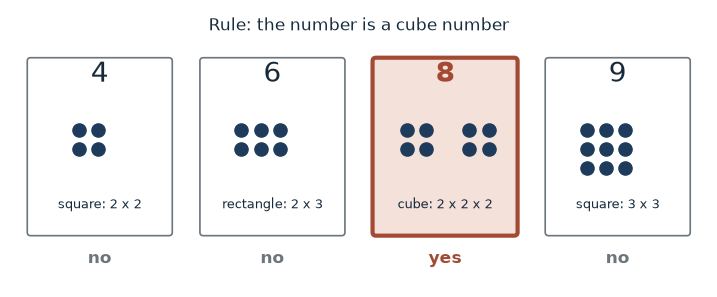

In [4]:
def dots(ax, n, x0, y0, step=0.28):
    """Draw n dots in the arrangement the chapter uses for that number."""
    if n == 8:    # a cube: two 2 x 2 layers side by side
        pts = [(x0 + c * step + 0.9 * layer, y0 - r * step) for layer in range(2) for r in range(2) for c in range(2)]
    elif n == 6:  # a 2 by 3 rectangle
        pts = [(x0 + c * step, y0 - r * step) for r in range(2) for c in range(3)]
    else:         # a square: 2 x 2 or 3 x 3
        side = int(round(n ** 0.5))
        pts = [(x0 + c * step, y0 - r * step) for r in range(side) for c in range(side)]
    ax.scatter([p[0] for p in pts], [p[1] for p in pts], s=90, color=NAVY, zorder=3)

fig, ax = plt.subplots(figsize=(9, 3.6))
for i, n in enumerate(numbers):
    x = i * 2.5
    hit = n in passes
    ax.add_patch(FancyBboxPatch((x, 0.9), 2.0, 2.5, boxstyle="round,pad=0.05",
                                facecolor=PICK if hit else "white",
                                edgecolor=RED if hit else GREY, linewidth=3 if hit else 1.2))
    ax.text(x + 1.0, 3.1, str(n), ha="center", fontsize=20, color=RED if hit else INK, fontweight="bold" if hit else "normal")
    start = {4: 0.7, 6: 0.55, 8: 0.45, 9: 0.55}[n]
    dots(ax, n, x + start, 2.4)
    label = {4: "square: 2 x 2", 6: "rectangle: 2 x 3", 8: "cube: 2 x 2 x 2", 9: "square: 3 x 3"}[n]
    ax.text(x + 1.0, 1.25, label, ha="center", fontsize=9.5)
    ax.text(x + 1.0, 0.45, "yes" if hit else "no", ha="center", fontsize=12, fontweight="bold", color=RED if hit else GREY)
ax.text(4.75, 3.85, "Rule: the number is a cube number", ha="center", fontsize=12.5)
ax.set_xlim(-0.3, 9.8); ax.set_ylim(0.1, 4.15)
blank(ax)
plt.show()

**What this shows.** Ask every number the same question: *is it a cube number, yes or no?* Only 8 says yes, so 8 is the odd one out. Switch to "is odd" and 9 is the odd one out. Switch to "is neither a square nor a cube" and it is 6. Switch to "is an even square" and it is 4. None of these choices is a matter of taste once the rule is written down: a stranger who tests 4, 6, 8, and 9 one at a time makes the same choice.

**Where it stops working.** Only these four numbers are tested. A rule singles out one number only if exactly one passes. "Is even" does not work as an odd-one-out rule, because three numbers pass it.

## 2. A list records, a rule decides

**The question.** If the boundary moves, which keeps up on its own: the list or the rule?

**The equation from the chapter.**

$$\{3, 6, 9, 12\}$$

**What the symbols mean.** The curly braces hold the *members* of a set. The rule here is "whole numbers from 1 through the boundary that are divisible by 3." A number belongs when it splits into groups of 3 with none left over. We start with the boundary at 12, the book's own example.

**Try to predict first.** Move the boundary from 12 to 15. Will the old list $\{3, 6, 9, 12\}$ still match the rule?

In [5]:
old_list = [3, 6, 9, 12]

def members(top):
    return [n for n in range(1, top + 1) if n % 3 == 0]

top = 12
m = members(top)
print(f"Boundary: whole numbers 1 through {top}")
print("Which numbers split into groups of 3 with none left?")
for n in range(1, top + 1):
    q, r = divmod(n, 3)
    print(f"  {n:2d} = {q} x 3 + {r}   ->  {'member' if r == 0 else 'not a member'}")
print()
print("Members by the rule:", as_set(m), " count =", len(m))
print("Groups:", ", ".join(f"{k} = {k // 3} x 3" for k in m))
print("Old list", as_set(old_list), "matches the rule:", m == old_list)

Boundary: whole numbers 1 through 12
Which numbers split into groups of 3 with none left?
   1 = 0 x 3 + 1   ->  not a member
   2 = 0 x 3 + 2   ->  not a member
   3 = 1 x 3 + 0   ->  member
   4 = 1 x 3 + 1   ->  not a member
   5 = 1 x 3 + 2   ->  not a member
   6 = 2 x 3 + 0   ->  member
   7 = 2 x 3 + 1   ->  not a member
   8 = 2 x 3 + 2   ->  not a member
   9 = 3 x 3 + 0   ->  member
  10 = 3 x 3 + 1   ->  not a member
  11 = 3 x 3 + 2   ->  not a member
  12 = 4 x 3 + 0   ->  member

Members by the rule: {3, 6, 9, 12}  count = 4
Groups: 3 = 1 x 3, 6 = 2 x 3, 9 = 3 x 3, 12 = 4 x 3
Old list {3, 6, 9, 12} matches the rule: True


Now the other boundaries in the reader's menu, including the one the prediction question asks about:

In [6]:
print(f"{'Through':8s}{'Members by the rule':36s}{'Count':7s}Old list")
for top in [10, 12, 15, 18]:
    m = members(top)
    print(f"{top:<8d}{as_set(m):36s}{len(m):<7d}{'matches' if m == old_list else 'needs updating'}")

Through Members by the rule                 Count  Old list
10      {3, 6, 9}                           3      needs updating
12      {3, 6, 9, 12}                       4      matches
15      {3, 6, 9, 12, 15}                   5      needs updating
18      {3, 6, 9, 12, 15, 18}               6      needs updating


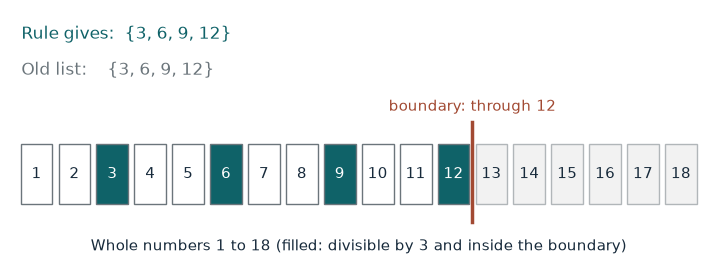

In [7]:
top = 12
fig, ax = plt.subplots(figsize=(9, 2.9))
for n in range(1, 19):
    inside = n <= top
    hit = inside and n % 3 == 0
    ax.add_patch(Rectangle((n - 0.42, 0.6), 0.84, 0.84, facecolor=TEAL if hit else ("#e6e6e6" if not inside else "white"),
                           edgecolor=GREY, alpha=1 if inside else 0.5))
    ax.text(n, 1.02, str(n), ha="center", va="center", color="white" if hit else INK)
ax.plot([top + 0.5] * 2, [0.35, 1.75], color=RED, linewidth=2.5)
ax.text(top + 0.5, 1.9, f"boundary: through {top}", ha="center", color=RED)
ax.text(0.6, 2.9, f"Rule gives:  {as_set(members(top))}", color=TEAL, fontsize=12)
ax.text(0.6, 2.4, f"Old list:    {as_set(old_list)}", color=GREY, fontsize=12)
ax.set_xlim(0.3, 18.7); ax.set_ylim(0.2, 3.3)
blank(ax)
ax.set_xlabel("Whole numbers 1 to 18 (filled: divisible by 3 and inside the boundary)")
plt.show()

**What this shows.** Through 12, the rule keeps $3 = 1 \times 3$, $6 = 2 \times 3$, $9 = 3 \times 3$, $12 = 4 \times 3$, and the list agrees. Move the boundary to 15 and the rule admits 15 at once ($15 = 5 \times 3$), while the old list has to be rewritten by hand. A list is a record of one moment. A rule is a method that keeps working.

**Where it stops working.** The numbers are whole numbers starting at 1, and "through" means the boundary itself counts. Change "through 15" to "less than 15" and 15 drops out.

## 3. Two rules on six cards

**The question.** Which cards meet both rules, at least one, or neither?

**The equations from the chapter.**

$$K = \{A, C, D\} \qquad\qquad K \cap C = \{C\}$$

**What the symbols mean.** $K$ is the set of cards sent by a listed contact. $C$ is the set of cards asking for a one-time code. The symbol $\cap$ means "in both." $U$ is the *universe*: the six cards on the table, and nothing else. We start with the question "in $K$ and in $C$."

**Try to predict first.** Which three cards sit outside $K$, and is Card B one of them?

In [8]:
# For each card: (is it from a listed contact?  does it ask for a code?)
cards = {"A": (True, False), "B": (False, True), "C": (True, True),
         "D": (True, False), "E": (False, False), "F": (False, False)}
yn = lambda b: "yes" if b else "no"

print("Step 1: ask each question separately for each card.")
for name, (k, c) in cards.items():
    print(f"  Card {name}: in K? {yn(k):3s}  in C? {yn(c):3s}")
K = [n for n, (k, c) in cards.items() if k]
Cc = [n for n, (k, c) in cards.items() if c]
print()
print("K =", as_set(K), "  C =", as_set(Cc))
both = [n for n in cards if n in K and n in Cc]
print("Step 2: in K and in C needs yes AND yes:", as_set(both))
print(f"Count: {len(both)} qualify + {6 - len(both)} left out = {len(both) + 6 - len(both)} cards in the universe")

Step 1: ask each question separately for each card.
  Card A: in K? yes  in C? no 
  Card B: in K? no   in C? yes
  Card C: in K? yes  in C? yes
  Card D: in K? yes  in C? no 
  Card E: in K? no   in C? no 
  Card F: in K? no   in C? no 

K = {A, C, D}   C = {B, C}
Step 2: in K and in C needs yes AND yes: {C}
Count: 1 qualify + 5 left out = 6 cards in the universe


The other three questions in the reader's menu:

In [9]:
ops = {
    "in K and in C (intersection)":  lambda k, c: k and c,
    "in K or in C (union)":          lambda k, c: k or c,
    "outside K (complement of K)":   lambda k, c: not k,
    "outside C (complement of C)":   lambda k, c: not c,
}
for words, test in ops.items():
    chosen = [n for n, (k, c) in cards.items() if test(k, c)]
    print(f"{words:30s} {as_set(chosen):22s} {len(chosen)} + {6 - len(chosen)} = 6")

in K and in C (intersection)   {C}                    1 + 5 = 6
in K or in C (union)           {A, B, C, D}           4 + 2 = 6
outside K (complement of K)    {B, E, F}              3 + 3 = 6
outside C (complement of C)    {A, D, E, F}           4 + 2 = 6


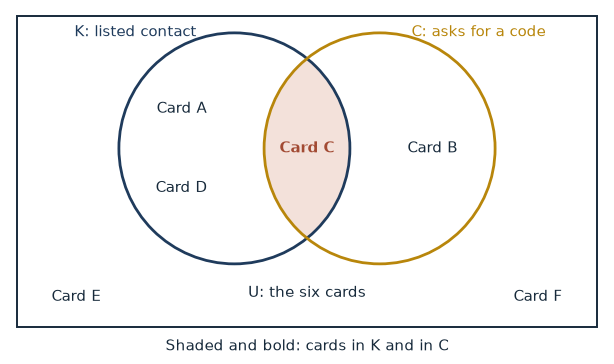

In [10]:
spots = {"A": (2.6, 3.4), "D": (2.6, 2.2), "C": (4.5, 2.8), "B": (6.4, 2.8), "E": (1.0, 0.55), "F": (8.0, 0.55)}
chosen = both
fig, ax = plt.subplots(figsize=(8, 4.2))
ax.add_patch(Rectangle((0.1, 0.1), 8.8, 4.7, facecolor="white", edgecolor=INK, linewidth=1.4))
kc = Circle((3.4, 2.8), 1.75, facecolor="none", edgecolor=NAVY, linewidth=2, zorder=3)
cc = Circle((5.6, 2.8), 1.75, facecolor="none", edgecolor=GOLD, linewidth=2, zorder=3)
shade = Circle((3.4, 2.8), 1.75, facecolor=PICK, edgecolor="none", zorder=1)   # the overlap: K clipped by C
ax.add_patch(shade)
shade.set_clip_path(Circle((5.6, 2.8), 1.75, transform=ax.transData))
ax.add_patch(kc); ax.add_patch(cc)
ax.text(1.9, 4.5, "K: listed contact", ha="center", color=NAVY)
ax.text(7.1, 4.5, "C: asks for a code", ha="center", color=GOLD)
ax.text(4.5, 0.55, "U: the six cards", ha="center")
for name, (x, y) in spots.items():
    hit = name in chosen
    ax.text(x, y, f"Card {name}", ha="center", va="center", zorder=5, color=RED if hit else INK, fontweight="bold" if hit else "normal")
ax.set_xlim(0, 9); ax.set_ylim(0, 4.9); ax.set_aspect("equal")
blank(ax)
ax.set_xlabel("Shaded and bold: cards in K and in C")
plt.show()

**What this shows.** The circles do not make any decisions. They only display the decisions already made in the table: each card answered two yes-or-no questions, and each question about the cards shades a different region. Only Card C answers yes to both, so $K \cap C = \{C\}$. Notice that the counts always add back to 6: every card in the universe has a place.

**Where it stops working.** The universe is exactly six invented cards. This is a sorting exercise, not advice about real messages. Without a stated universe, "outside K" would have no edge: outside of what?

## 4. Every number gets one location

**The question.** In $U = \{2, 3, 4, 5, 6, 7\}$, where does each number land when two rules ask their questions?

**The equations from the chapter.**

$$E = \{2, 4, 6\} \qquad\qquad G = \{5, 6, 7\}$$

**What the symbols mean.** $E$ is the even numbers in $U$. $G$ is the numbers in $U$ greater than the chosen boundary, which starts at 4 (so 4 itself is *not* in $G$). Two yes-or-no answers give four possible locations: in both, in $E$ only, in $G$ only, in neither.

**Try to predict first.** Raise the boundary from 4 to 5. Where does 5 move, and does the overlap $\{6\}$ change?

In [11]:
U = [2, 3, 4, 5, 6, 7]

def locations(boundary):
    E = [n for n in U if n % 2 == 0]
    G = [n for n in U if n > boundary]
    return E, G, {
        "both E and G": [n for n in U if n in E and n in G],
        "E only":       [n for n in U if n in E and n not in G],
        "G only":       [n for n in U if n not in E and n in G],
        "neither":      [n for n in U if n not in E and n not in G],
    }

b = 4
E, G, where = locations(b)
print(f"Boundary: greater than {b}")
for n in U:
    print(f"  {n}: even? {yn(n % 2 == 0):3s}  {n} > {b}? {yn(n > b):3s}")
print()
print("E =", as_set(E), "  G =", as_set(G))
print("Overlap (in both):", as_set(where["both E and G"]), ", since 6 is even and 6 > 4")
print("Outside both:", as_set(where["neither"]))
sizes = [len(v) for v in where.values()]
print("Count the four locations:", " + ".join(str(s) for s in sizes), "=", sum(sizes))

Boundary: greater than 4
  2: even? yes  2 > 4? no 
  3: even? no   3 > 4? no 
  4: even? yes  4 > 4? no 
  5: even? no   5 > 4? yes
  6: even? yes  6 > 4? yes
  7: even? no   7 > 4? yes

E = {2, 4, 6}   G = {5, 6, 7}
Overlap (in both): {6} , since 6 is even and 6 > 4
Outside both: {3}
Count the four locations: 1 + 2 + 2 + 1 = 6


The other boundaries from the reader's menu:

In [12]:
print(f"{'Boundary':9s}{'G':16s}{'Overlap':11s}{'Outside both':14s}Locations add up")
for b in [3, 4, 5, 7]:
    E, G, where = locations(b)
    s = [len(v) for v in where.values()]
    print(f"{b:<9d}{as_set(G):16s}{as_set(where['both E and G']):11s}{as_set(where['neither']):14s}{' + '.join(map(str, s))} = {sum(s)}")

Boundary G               Overlap    Outside both  Locations add up
3        {4, 5, 6, 7}    {4, 6}     {3}           2 + 1 + 2 + 1 = 6
4        {5, 6, 7}       {6}        {3}           1 + 2 + 2 + 1 = 6
5        {6, 7}          {6}        {3, 5}        1 + 2 + 1 + 2 = 6
7        { }             { }        {3, 5, 7}     0 + 3 + 0 + 3 = 6


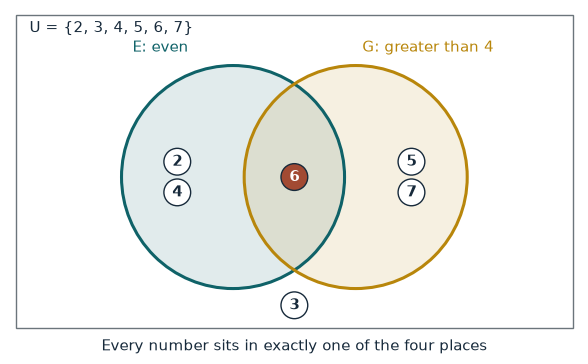

In [13]:
b = 4
E, G, where = locations(b)
fig, ax = plt.subplots(figsize=(8, 4.2))
ax.add_patch(Rectangle((0, 0), 10, 5.6, facecolor="white", edgecolor=GREY))
ax.text(0.25, 5.3, "U = {2, 3, 4, 5, 6, 7}", fontsize=11)
for centre, col in [((3.9, 2.7), TEAL), ((6.1, 2.7), GOLD)]:
    ax.add_patch(Circle(centre, 2.0, facecolor=col, alpha=0.12, edgecolor="none"))
    ax.add_patch(Circle(centre, 2.0, facecolor="none", edgecolor=col, linewidth=2.2, zorder=3))
ax.text(2.6, 4.95, "E: even", ha="center", color=TEAL)
ax.text(7.4, 4.95, f"G: greater than {b}", ha="center", color=GOLD)
spots = {"E only": (2.9, 2.7), "both E and G": (5.0, 2.7), "G only": (7.1, 2.7), "neither": (5.0, 0.4)}
for name, (cx, cy) in spots.items():
    mem = where[name]
    for j, n in enumerate(mem):
        if name == "neither":
            x, y = cx + 0.62 * (j - (len(mem) - 1) / 2), cy
        else:
            x, y = cx, cy + 0.55 * ((len(mem) - 1) / 2 - j)
        hit = name == "both E and G"
        ax.add_patch(Circle((x, y), 0.24, facecolor=RED if hit else "white", edgecolor=INK, zorder=4))
        ax.text(x, y, str(n), ha="center", va="center", zorder=5, color="white" if hit else INK, fontweight="bold")
ax.set_xlim(-0.1, 10.1); ax.set_ylim(-0.1, 5.7); ax.set_aspect("equal")
blank(ax)
ax.set_xlabel("Every number sits in exactly one of the four places")
plt.show()

**What this shows.** Even numbers are $\{2, 4, 6\}$. Greater than 4 is $\{5, 6, 7\}$. Only 6 is in both. The number 3 is outside both, and $1 + 2 + 2 + 1 = 6$ confirms that every number has exactly one place. Raise the boundary to 5 and the overlap is still $\{6\}$, but $G$ shrinks to $\{6, 7\}$, so 5 moves to "neither."

**Where it stops working.** The universe is fixed at 2 through 7, and "greater than" excludes the boundary itself. When the boundary reaches 7, $G$ is empty, and so is the overlap. An empty overlap is a real answer, not a mistake.

## Practice

Try each one with pencil and paper first, then open the answer.

**1.** Under the rule "is even," how many of 4, 6, 8, 9 pass, and does that rule single one out?

<details><summary>Show answer</summary>

Pair each number up and see what is left:

- 4 = 2 pairs, 0 left, so it passes.
- 6 = 3 pairs, 0 left, so it passes.
- 8 = 4 pairs, 0 left, so it passes.
- 9 = 4 pairs + 1 left, so it fails.

Three numbers pass: 3. A rule that three numbers pass does not single one out. (It does single out 9 by *failing* it, but that is a different question.)
</details>

**2.** With the boundary through 21, how many members does the rule "divisible by 3" give, and what is the largest?

<details><summary>Show answer</summary>

Count how many groups of 3 fit: 21 = 7 x 3, so the multiples are $3 \times 1$ through $3 \times 7$.

Members: 3, 6, 9, 12, 15, 18, 21. That is 7 members, and the largest is 21.
</details>

**3.** If $G$ meant "at least 4" instead of "greater than 4," what would the overlap be?

<details><summary>Show answer</summary>

"At least 4" includes 4 itself, so $G = \{4, 5, 6, 7\}$.

Even numbers in $G$: 4 is even, 5 is not, 6 is even, 7 is not.

Overlap = $\{4, 6\}$. One tiny wording change moved a number across the boundary, which is why the rule has to be stated exactly.
</details>